# Adjoint vs finite differences: gradient of a PDE model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/auto-differentiation/xad-py/blob/main/notebooks/03_adjoint_vs_finite_differences.ipynb)

A typical inverse problem: a diffusion model has an unknown, spatially varying diffusivity `k(x)`, and we measure the
final state. Fitting `k` to the data means minimising a least-squares misfit, and gradient-based optimisers need the
gradient of that misfit with respect to **every** parameter.

- Finite differences: one extra simulation per parameter, so cost grows with the number of parameters `n`.
- Adjoint mode: one recorded simulation plus one backward pass, whatever `n` is.

This notebook measures both as `n` grows.

In [1]:
%pip install -q xad

Note: you may need to restart the kernel to use updated packages.


## The model

1D heat equation `u_t = (k(x) u_x)_x` on `n` cells, no-flux boundaries, explicit time stepping. The code is plain
Python; it runs on floats or on XAD numbers.

In [2]:
import math
import time

import matplotlib.pyplot as plt
import xad.adj_1st as xadj


def simulate(k, u0, steps=100, lam=0.2):
    n = len(u0)
    u = list(u0)
    k_face = [0.5 * (k[i] + k[i + 1]) for i in range(n - 1)]
    for _ in range(steps):
        flux = [k_face[i] * (u[i + 1] - u[i]) for i in range(n - 1)]
        u = ([u[0] + lam * flux[0]]
             + [u[i] + lam * (flux[i] - flux[i - 1]) for i in range(1, n - 1)]
             + [u[-1] - lam * flux[-1]])
    return u


def misfit(k, u0, observed):
    u = simulate(k, u0)
    return sum((a - b) ** 2 for a, b in zip(u, observed))


def problem(n):
    """Initial state, synthetic observations from a 'true' diffusivity, and a first guess."""
    u0 = [math.sin(math.pi * (i + 0.5) / n) ** 2 for i in range(n)]
    k_true = [1.0 + 0.5 * math.sin(3.0 * i / n) for i in range(n)]
    return u0, simulate(k_true, u0), [1.0] * n

## The two ways to get the gradient

In [3]:
def gradient_fd(k, u0, observed, h=1e-6):
    """Forward finite differences: n + 1 simulations."""
    base = misfit(k, u0, observed)
    grad = []
    for i in range(len(k)):
        bumped = list(k)
        bumped[i] += h
        grad.append((misfit(bumped, u0, observed) - base) / h)
    return grad


def gradient_adjoint(k, u0, observed):
    """XAD adjoint mode: one recorded simulation + one backward pass."""
    k_ad = [xadj.Real(v) for v in k]
    with xadj.Tape() as tape:
        tape.registerInputs(k_ad)
        tape.newRecording()
        J = misfit(k_ad, u0, observed)
        tape.registerOutput(J)
        J.derivative = 1.0
        tape.computeAdjoints()
        return [ki.derivative for ki in k_ad]

## Accuracy

On a small grid, both agree. The finite-difference error comes from the bump size; the adjoint gradient is exact to
rounding.

In [4]:
u0, observed, k = problem(20)
g_fd = gradient_fd(k, u0, observed)
g_ad = gradient_adjoint(k, u0, observed)

scale = max(abs(g) for g in g_ad)
print(f"max |gradient|             = {scale:.3e}")
print(f"max |adjoint - finite diff| = {max(abs(a - b) for a, b in zip(g_ad, g_fd)):.3e}")

max |gradient|             = 1.007e-02
max |adjoint - finite diff| = 8.279e-09


## Cost as the number of parameters grows

In [5]:
sizes = [25, 50, 100, 200, 400]
t_fd, t_ad = [], []

print(f"{'n':>5} {'finite diff [s]':>16} {'XAD adjoint [s]':>16} {'speed-up':>9}")
for n in sizes:
    u0, observed, k = problem(n)
    t0 = time.perf_counter()
    gradient_fd(k, u0, observed)
    t_fd.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    gradient_adjoint(k, u0, observed)
    t_ad.append(time.perf_counter() - t0)
    print(f"{n:5d} {t_fd[-1]:16.3f} {t_ad[-1]:16.3f} {t_fd[-1] / t_ad[-1]:8.1f}x")

    n  finite diff [s]  XAD adjoint [s]  speed-up
   25            0.023            0.033      0.7x
   50            0.074            0.068      1.1x
  100            0.355            0.125      2.8x
  200            1.375            0.397      3.5x
  400            5.163            0.472     10.9x


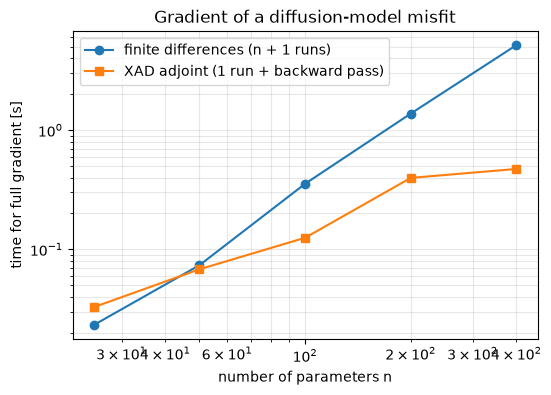

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(sizes, t_fd, "o-", label="finite differences (n + 1 runs)")
ax.loglog(sizes, t_ad, "s-", label="XAD adjoint (1 run + backward pass)")
ax.set_xlabel("number of parameters n")
ax.set_ylabel("time for full gradient [s]")
ax.set_title("Gradient of a diffusion-model misfit")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

With a handful of parameters, finite differences are competitive. But they cost one simulation per parameter, so on this model (where each simulation also grows with
`n`) the time grows roughly with `n²`. The adjoint gradient costs a fixed multiple of one simulation, so the gap widens
with every parameter added. In the compiled C++ library the per-operation overhead is far lower still.

## Next steps

- [XAD quickstart](https://colab.research.google.com/github/auto-differentiation/xad-py/blob/main/notebooks/01_quickstart.ipynb)
- [Python documentation](https://auto-differentiation.github.io/tutorials/python) and the [XAD C++ library](https://github.com/auto-differentiation/xad).